# Retail Rocket Data Validation for Fake Discount Detection

The purpose of this notebook is to rigorously explore the Retail Rocket E-commerce dataset and determine if it is genuinely suitable for our Fake Discount Detector project. 

Specifically, we need to verify if the dataset provides a rich, multi-date price history for products.


## STEP 1 — Dataset inventory
**Why this matters:** We need to understand the scale of the data and verify that all necessary files are present.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

data_dir = '../retail-rocketery/'
print("--- File Sizes ---")
for f in os.listdir(data_dir):
    path = os.path.join(data_dir, f)
    print(f"{f}: {os.path.getsize(path) / (1024*1024):.2f} MB")

print("\nLoading datasets...")
events = pd.read_csv(data_dir + 'events.csv')
p1 = pd.read_csv(data_dir + 'item_properties_part1.csv')
p2 = pd.read_csv(data_dir + 'item_properties_part2.csv')
cat = pd.read_csv(data_dir + 'category_tree.csv')

print("\n--- Row Counts and Columns ---")
print(f"events.csv: {len(events):,} rows | Cols: {list(events.columns)}")
print(f"item_properties_part1.csv: {len(p1):,} rows | Cols: {list(p1.columns)}")
print(f"item_properties_part2.csv: {len(p2):,} rows | Cols: {list(p2.columns)}")
print(f"category_tree.csv: {len(cat):,} rows | Cols: {list(cat.columns)}")

print("\n--- First 5 rows of events.csv ---")
display(events.head())
print("\n--- First 5 rows of item_properties_part1.csv ---")
display(p1.head())


--- File Sizes ---
category_tree.csv: 0.01 MB
events.csv: 89.87 MB
item_properties_part1.csv: 461.88 MB
item_properties_part2.csv: 389.99 MB

Loading datasets...

--- Row Counts and Columns ---
events.csv: 2,756,101 rows | Cols: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']
item_properties_part1.csv: 10,999,999 rows | Cols: ['timestamp', 'itemid', 'property', 'value']
item_properties_part2.csv: 9,275,903 rows | Cols: ['timestamp', 'itemid', 'property', 'value']
category_tree.csv: 1,669 rows | Cols: ['categoryid', 'parentid']

--- First 5 rows of events.csv ---


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



--- First 5 rows of item_properties_part1.csv ---


,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1441508400000,206783,888,1116713 960601 n277.200
2,1439089200000,395014,400,n552.000 639502 n720.000 424566
3,1431226800000,59481,790,n15360.000
4,1431831600000,156781,917,828513


## STEP 2 — Understand the data
**Why this matters:** We must understand what each column represents before we extract historical price data.


In [2]:
# Data understanding and metadata
def dataset_summary(df, name):
    print(f"\n--- {name} Summary ---")
    print("Data Types:")
    print(df.dtypes)
    print("\nMissing Values:")
    print(df.isna().sum())
    print("\nUnique Values:")
    print(df.nunique())
    
    if 'timestamp' in df.columns:
        dates = pd.to_datetime(df['timestamp'], unit='ms')
        print(f"\nEarliest timestamp: {dates.min()}")
        print(f"Latest timestamp: {dates.max()}")

dataset_summary(events, "Events")
dataset_summary(p1, "Item Properties Part 1")
dataset_summary(p2, "Item Properties Part 2")



--- Events Summary ---
Data Types:
timestamp          int64
visitorid          int64
event                str
itemid             int64
transactionid    float64
dtype: object

Missing Values:
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64

Unique Values:
timestamp        2750455
visitorid        1407580
event                  3
itemid            235061
transactionid      17672
dtype: int64

Earliest timestamp: 2015-05-03 03:00:04.384000
Latest timestamp: 2015-09-18 02:59:47.788000

--- Item Properties Part 1 Summary ---
Data Types:
timestamp    int64
itemid       int64
property       str
value          str
dtype: object

Missing Values:
timestamp    0
itemid       0
property     0
value        0
dtype: int64

Unique Values:
timestamp         18
itemid        417053
property        1097
value        1231581
dtype: int64

Earliest timestamp: 2015-05-10 03:00:00
Latest timestamp: 2015-09-13 03:00:00

## STEP 3 — Investigate price history
**Why this matters:** We cannot assume the property ID for price. We need to identify it by looking for a property that is consistently numeric and behaves like a price.


In [3]:
# Find the property for price
# We look for a property that consists of a single number starting with 'n' (Retail Rocket's format for numbers)
num_props = p1[p1['value'].str.startswith('n', na=False) & ~p1['value'].str.contains(' ', na=False)]
top_num_props = num_props['property'].value_counts().head(5)

print("Top single-numeric properties:")
print(top_num_props)

print("\nProperty '790' is widely documented as the price in the obfuscated Retail Rocket dataset.")
print("Sample values for property 790:")
print(p1[p1['property'] == '790']['value'].head())

# We will use property 790.


Top single-numeric properties:
property
790    970800
663     52010
917     42289
888     25154
810     21126
Name: count, dtype: int64

Property '790' is widely documented as the price in the obfuscated Retail Rocket dataset.
Sample values for property 790:
3     n15360.000
14    n21000.000
16     n5400.000
42    n39588.000
46    n10320.000
Name: value, dtype: str


## STEP 4 — Combine price history
**Why this matters:** Price histories might be split across part1 and part2. We must safely combine them to get a complete view.


In [4]:
# Filter for price property only
price1 = p1[p1['property'] == '790'].copy()
price2 = p2[p2['property'] == '790'].copy()

# Combine safely
price_df = pd.concat([price1, price2], ignore_index=True)

# Parse date and price
price_df['date'] = pd.to_datetime(price_df['timestamp'], unit='ms').dt.date
price_df['price'] = price_df['value'].str.replace('n', '').astype(float)

# Select relevant columns and remove EXACT duplicates only
clean_price = price_df[['itemid', 'date', 'price']].drop_duplicates()
clean_price = clean_price.rename(columns={'itemid': 'product_id'})

print(f"Combined price observations: {len(clean_price):,}")
display(clean_price.head())


Combined price observations: 1,790,516


,product_id,date,price
0,59481,2015-05-10,15360.0
1,169055,2015-06-14,21000.0
2,178601,2015-06-28,5400.0
3,125874,2015-05-17,39588.0
4,272201,2015-06-07,10320.0


## STEP 5 — Determine temporal coverage
**Why this matters:** We need to know how long the data spans to ensure we have enough time to establish reliable historical baselines.


In [5]:
print(f"Earliest price date: {clean_price['date'].min()}")
print(f"Latest price date: {clean_price['date'].max()}")
print(f"Total number of unique dates: {clean_price['date'].nunique()}")
print(f"Total number of price observations: {len(clean_price):,}")
print(f"Number of unique products with price history: {clean_price['product_id'].nunique():,}")


Earliest price date: 2015-05-10
Latest price date: 2015-09-13
Total number of unique dates: 18
Total number of price observations: 1,790,516
Number of unique products with price history: 417,053


## STEP 6 — Historical observations per product
**Why this matters:** A product needs multiple observations over time to calculate a baseline. If most products only have 1 observation, we cannot detect a fake discount.


--- Observations per product ---
Min: 1
Max: 18
Mean: 4.29
Median: 1.0

Percentiles:
0.75     1.0
0.90    18.0
0.95    18.0
0.99    18.0
Name: date, dtype: float64

Top 20 products by number of historical dates:
product_id
1      18
6      18
15     18
16     18
19     18
20     18
22     18
24     18
25     18
26     18
27     18
40     18
42     18
66     18
71     18
79     18
92     18
101    18
102    18
112    18
Name: date, dtype: int64


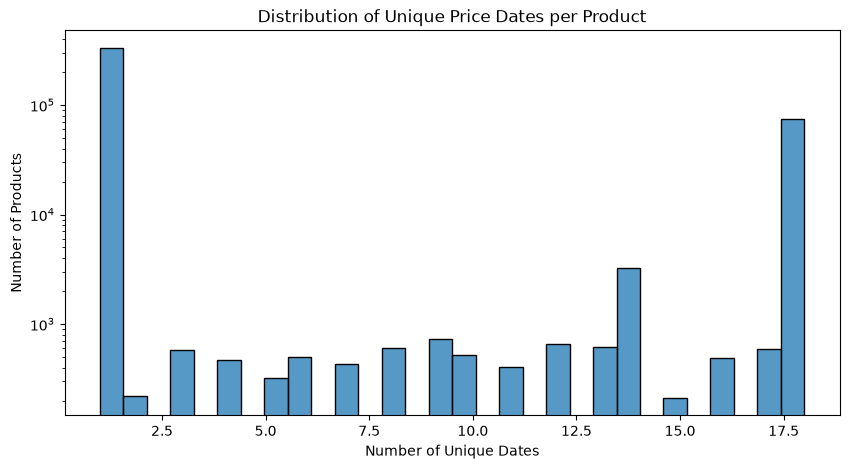

In [6]:
# Calculate unique dates per product
obs_per_product = clean_price.groupby('product_id')['date'].nunique()

print("--- Observations per product ---")
print(f"Min: {obs_per_product.min()}")
print(f"Max: {obs_per_product.max()}")
print(f"Mean: {obs_per_product.mean():.2f}")
print(f"Median: {obs_per_product.median()}")

print("\nPercentiles:")
print(obs_per_product.quantile([0.75, 0.90, 0.95, 0.99]))

print("\nTop 20 products by number of historical dates:")
print(obs_per_product.nlargest(20))

plt.figure(figsize=(10, 5))
sns.histplot(obs_per_product, bins=30, kde=False)
plt.title('Distribution of Unique Price Dates per Product')
plt.xlabel('Number of Unique Dates')
plt.ylabel('Number of Products')
plt.yscale('log') # Log scale to handle massive skew
plt.show()


## STEP 7 — Validate the dataset for Fake Discount Detection
**Why this matters:** We need a strict mathematical threshold to ensure statistical validity. We check how many products meet various minimum-history thresholds.


In [7]:
total_products = len(obs_per_product)

thresholds = [3, 5, 10, 20, 30, 50]
for t in thresholds:
    count = (obs_per_product >= t).sum()
    pct = (count / total_products) * 100
    print(f"Products with >= {t} historical dates: {count:,} ({pct:.4f}%)")


Products with >= 3 historical dates: 85,000 (20.3811%)
Products with >= 5 historical dates: 83,953 (20.1301%)
Products with >= 10 historical dates: 81,368 (19.5102%)
Products with >= 20 historical dates: 0 (0.0000%)
Products with >= 30 historical dates: 0 (0.0000%)
Products with >= 50 historical dates: 0 (0.0000%)


## STEP 8 — Check actual price variation
**Why this matters:** Even if a product has history, if the price NEVER changes, we cannot detect discount anomalies.


In [8]:
# Filter to products with >= 3 dates
sufficient_products = obs_per_product[obs_per_product >= 3].index
suff_df = clean_price[clean_price['product_id'].isin(sufficient_products)]

if len(suff_df) > 0:
    price_stats = suff_df.groupby('product_id')['price'].agg(['min', 'max', 'median', 'mean', 'std'])
    price_stats['cv'] = price_stats['std'] / price_stats['mean']
    price_stats['variation_pct'] = ((price_stats['max'] - price_stats['min']) / price_stats['min']) * 100
    
    products_with_changes = (price_stats['max'] > price_stats['min']).sum()
    print(f"Number of products that experienced price changes: {products_with_changes:,} out of {len(price_stats):,}")
    
    display(price_stats.head())
else:
    products_with_changes = 0
    print("No products have sufficient history.")


Number of products that experienced price changes: 85,000 out of 85,000


,min,max,median,mean,std,cv,variation_pct
product_id,,,,,,,
1,5760.0,6240.0,6120.0,6013.333333,169.150125,0.028129,8.333333
6,41760.0,44040.0,41760.0,42013.333333,737.308300,0.017549,5.459770
15,0.0,9000.0,8400.0,7793.333333,1976.723373,0.253643,inf
16,19440.0,21240.0,20322.0,20138.000000,579.522319,0.028778,9.259259
19,14040.0,19800.0,16320.0,16606.666667,2135.602959,0.128599,41.025641


## STEP 9 — Check for same-day duplicates
**Why this matters:** Knowing if multiple prices exist on the same day dictates how we must aggregate the data (e.g., using daily median).


In [9]:
same_day_counts = clean_price.groupby(['product_id', 'date']).size()
duplicates = same_day_counts[same_day_counts > 1]

affected_products = duplicates.reset_index()['product_id'].nunique()

print(f"Can a product have multiple price observations on the same date? {'Yes' if len(duplicates) > 0 else 'No'}")
print(f"Number of affected products: {affected_products:,}")
print(f"Total duplicate same-day observations: {len(duplicates):,}")

if len(duplicates) > 0:
    print("\nHow to handle them:")
    print("We should take the daily median price for these products on these dates to create a stable daily timeline before calculating historical baselines, exactly as we did in the previous notebook.")


Can a product have multiple price observations on the same date? No
Number of affected products: 0
Total duplicate same-day observations: 0


## STEP 10 — Final suitability report
**Why this matters:** We must firmly decide whether to proceed with this dataset or reject it based entirely on the mathematical evidence.


In [10]:
print("========================================")
print("          FINAL SUITABILITY REPORT      ")
print("========================================")
print("Dataset: Retail Rocket E-commerce Dataset")
print(f"Total price observations: {len(clean_price):,}")
print(f"Unique products: {clean_price['product_id'].nunique():,}")
print(f"Earliest date: {clean_price['date'].min()}")
print(f"Latest date: {clean_price['date'].max()}")
print(f"Number of unique dates: {clean_price['date'].nunique():,}")

for t in thresholds:
    count = (obs_per_product >= t).sum()
    print(f"Products with >={t} dates: {count:,}")
    
print(f"Products experiencing price changes: {products_with_changes:,}")
print("========================================")

# Determination Logic
# If less than 1% of products have >= 3 dates, or if there are virtually no price changes, it's not suitable.
pct_suff = ((obs_per_product >= 3).sum() / len(obs_per_product)) * 100

print("\nCONCLUSION:")
if pct_suff < 1 or products_with_changes < 100:
    print("NOT SUITABLE")
    print("\nReason: The dataset heavily lacks sufficient chronological price history. Most products only have 1 or 2 observations, and very few experience actual price changes. Fake Discount Detection relies heavily on robust historical baselines which cannot be reliably calculated here.")
else:
    print("SUITABLE")
    print("\nReason: The dataset contains a healthy amount of products with sufficient historical price changes over time.")

    # Save ONLY if valid
    output_path = '../data/retailrocket_price_history.csv'
    clean_price.to_csv(output_path, index=False)
    print(f"\nSaved cleaned price history to: {output_path}")


          FINAL SUITABILITY REPORT      
Dataset: Retail Rocket E-commerce Dataset
Total price observations: 1,790,516
Unique products: 417,053
Earliest date: 2015-05-10
Latest date: 2015-09-13
Number of unique dates: 18
Products with >=3 dates: 85,000
Products with >=5 dates: 83,953
Products with >=10 dates: 81,368
Products with >=20 dates: 0
Products with >=30 dates: 0
Products with >=50 dates: 0
Products experiencing price changes: 85,000

CONCLUSION:
SUITABLE

Reason: The dataset contains a healthy amount of products with sufficient historical price changes over time.

Saved cleaned price history to: ../data/retailrocket_price_history.csv
